In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:

df =pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")
print("Dataset Shape :",df.shape)
display(df.head())

Dataset Shape : (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
print("Rows and columns : ",df.shape)

print("\nColumn names : ")
print(df.columns.tolist())

print("\nDataset infromation: ")
df.info()


Rows and columns :  (7043, 21)

Column names : 
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Dataset infromation: 
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 

In [3]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [4]:
print(df["Churn"].value_counts())
print("\nChurn percentage : ")
print(
    (df["Churn"].value_counts(normalize=True)*100).round(2)
)

Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn percentage : 
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


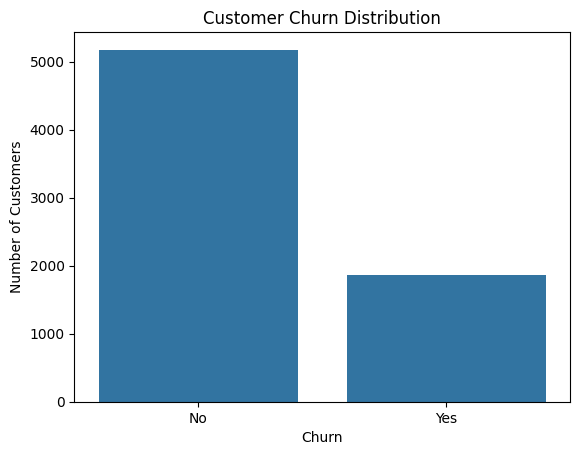

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df, x="Churn")
plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.show()

In [6]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


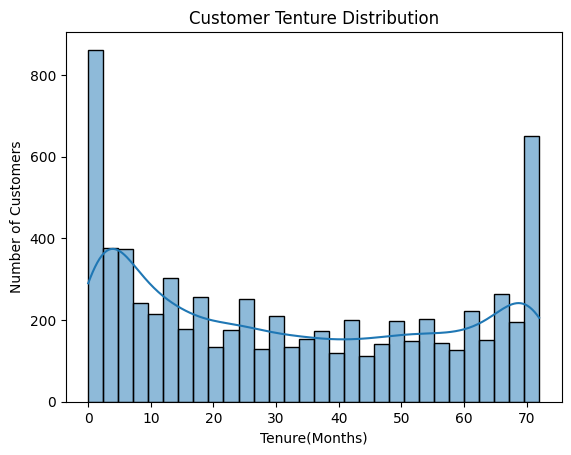

In [7]:
sns.histplot(data=df,x="tenure",bins=30,kde=True)
plt.title("Customer Tenture Distribution")
plt.xlabel("Tenure(Months)")
plt.ylabel("Number of Customers")
plt.show()

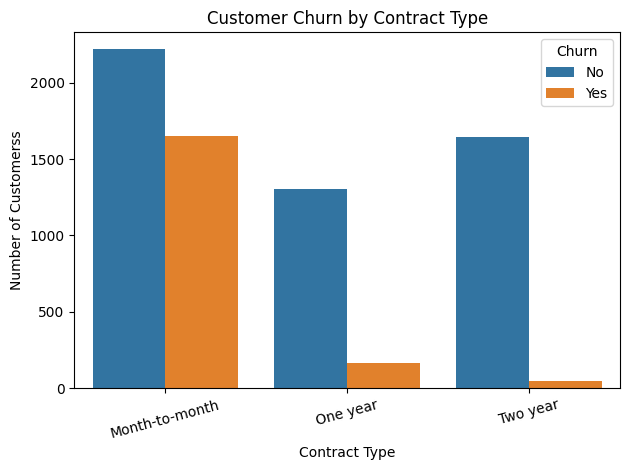

In [8]:
sns.countplot(data=df,x="Contract",hue="Churn")
plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customerss")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [12]:
# inspect TotalCharges

print("Datatype:",df['TotalCharges'].dtype)


# find the black/whitespace only entries

blank_charges = df['TotalCharges'].str.strip().eq("")

print("Blank TotalCharges: ",
      blank_charges.sum()
      )
# display which row are affected 

display(df.loc[blank_charges,["tenure","MonthlyCharges","TotalCharges","Churn"]])

Datatype: object
Blank TotalCharges:  11


,tenure,MonthlyCharges,TotalCharges,Churn
488,0,52.55,,No
753,0,20.25,,No
936,0,80.85,,No
1082,0,25.75,,No
1340,0,56.05,,No
3331,0,19.85,,No
3826,0,25.35,,No
4380,0,20.00,,No
5218,0,19.70,,No
6670,0,73.35,,No


now clean and convert

In [14]:
# convet blank strings ti missing value
df["TotalCharges"] = df["TotalCharges"].replace(r"^\s*$",np.nan,regex=True)


# convert the column to numeric
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"],errors="coerce")

# verifying the result

print("new Data type: ",
      df["TotalCharges"].dtype)

print("Missing values :",
      df["TotalCharges"].isnull().sum())


new Data type:  float64
Missing values : 11


In [15]:
display(df[df["TotalCharges"].isnull()])

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,No


In [16]:
print(df.loc[df["TotalCharges"].isnull(),"tenure"].value_counts())

tenure
0    11
Name: count, dtype: int64


In [17]:
df["TotalCharges"]= df["TotalCharges"].fillna(0)

print("Missing TotalCharges: ",
      df["TotalCharges"].isnull().sum())

Missing TotalCharges:  0


In [18]:
df[["tenure","MonthlyCharges","TotalCharges"]].head()

,tenure,MonthlyCharges,TotalCharges
0,1,29.85,29.85
1,34,56.95,1889.50
2,2,53.85,108.15
3,45,42.30,1840.75
4,2,70.70,151.65


In [19]:
print("Duplicate rows :",df.duplicated().sum())

Duplicate rows : 0


In [20]:
print("Unique Customer IDS : ",
      df["customerID"].unique())
print("Total Rows : ",len(df))

Unique Customer IDS :  ['7590-VHVEG' '5575-GNVDE' '3668-QPYBK' ... '4801-JZAZL' '8361-LTMKD'
 '3186-AJIEK']
Total Rows :  7043


verify the cleaned data 

In [25]:
print("Dataset shape :", df.shape)
print("Missing values :",
      df.isnull().sum().sum())
print("Duplicate rows : ",
      df.duplicated().sum())
print("Data types: ")
print(df.dtypes)

Dataset shape : (7043, 21)
Missing values : 0
Duplicate rows :  0
Data types: 
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                object
dtype: object


In [26]:
print("Unique Customer IDS : ",
      df["customerID"].unique())
print("Total Rows : ",len(df))

Unique Customer IDS :  ['7590-VHVEG' '5575-GNVDE' '3668-QPYBK' ... '4801-JZAZL' '8361-LTMKD'
 '3186-AJIEK']
Total Rows :  7043


x, y input x  taget y

In [27]:
# input features x
X=df.drop(columns=["Churn", "customerID"])

# target variable y
y= df["Churn"].map({"No":0, "Yes":1})

print("Features shape:",X.shape)
print("Target Shape: ",y.shape)

display(X.head())
display(y.head())

Features shape: (7043, 19)
Target Shape:  (7043,)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65


0    0
1    0
2    1
3    0
4    1
Name: Churn, dtype: int64

In [28]:
categorical_col=X.select_dtypes(include=["object"]).columns.tolist()

numerical_col=X.select_dtypes(exclude=["object"]).columns.tolist()

print("Categorical columns:",categorical_col)
print("Numerical columns:",numerical_col)

Categorical columns: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Numerical columns: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']


In [29]:
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test=train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples: ",X_train.shape[0])
print("Testing samples: ",X_test.shape[0])

Training samples:  5634
Testing samples:  1409


In [30]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder,StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import(
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

In [32]:
preprocessor = ColumnTransformer(
    transformers=[
        ("categorical",OneHotEncoder(handle_unknown="ignore"),categorical_col),
        ("numerical",StandardScaler(),numerical_col)
    ]
)

train logistic regression

In [34]:
model=Pipeline(
    steps=[
        ("preprocessor",preprocessor),
        ("classifier",LogisticRegression(max_iter=1000))
    ]
)
model.fit(X_train,y_train)
print("Model training completed")

Model training completed


In [38]:
y_pred=model.predict(X_test)
y_prob=model.predict_proba(X_test)[:,1]

print("Accuracy :",round(accuracy_score(y_test,y_pred),4))
print("ROC-AUC: ",round(roc_auc_score(y_test,y_prob),4))


Accuracy : 0.8055
ROC-AUC:  0.8421


In [39]:
print(classification_report(y_test,y_pred,target_names=["Stayed","Churned"]))

              precision    recall  f1-score   support

      Stayed       0.85      0.89      0.87      1035
     Churned       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



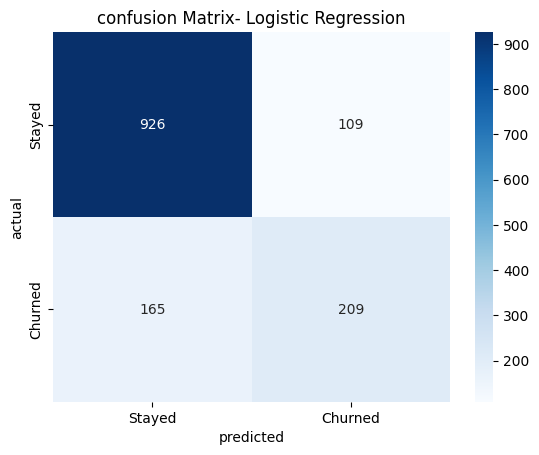

In [41]:
cm= confusion_matrix(y_test,y_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Stayed" , "Churned"],
    yticklabels=["Stayed" , "Churned"]
)

plt.xlabel("predicted")
plt.ylabel("actual")
plt.title("confusion Matrix- Logistic Regression")
plt.show()

In [42]:
from sklearn.ensemble import RandomForestClassifier


In [43]:
rf_model=Pipeline(
    steps=[
        ("preprocessor",preprocessor),
        ("classifier",RandomForestClassifier(
            n_estimators=200,
            random_state=42,
            class_weight="balanced",
            n_jobs=1
        ))

    ]
)
rf_model.fit(X_train,y_train)
print("Random forest training completed")

Random forest training completed


In [44]:
rf_pred=rf_model.predict(X_test)
rf_prob=rf_model.predict_proba(X_test)[:,1]

print("Accuracy :",round(accuracy_score(y_test,rf_pred),4))
print("ROC-AUC: ",round(roc_auc_score(y_test,rf_prob),4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    rf_pred,
    target_names=["Stayed","Churned"]
))

Accuracy : 0.7857
ROC-AUC:  0.8201

Classification Report:
              precision    recall  f1-score   support

      Stayed       0.83      0.90      0.86      1035
     Churned       0.62      0.48      0.54       374

    accuracy                           0.79      1409
   macro avg       0.73      0.69      0.70      1409
weighted avg       0.77      0.79      0.78      1409



compare both models

In [46]:
comparison=pd.DataFrame({
    "Model":["Logistic Regression","Random Forest"],
    "Accuracy":[accuracy_score(y_test,y_pred),accuracy_score(y_test,rf_pred)],
    "ROC-AUC":[roc_auc_score(y_test,y_prob),roc_auc_score(y_test,rf_prob)],
    "Churn Recall":[classification_report(
        y_test,y_pred,output_dict=True)["1"]["recall"],
        classification_report(
            y_test,rf_pred,output_dict=True)["1"]["recall"]
    ],
    "Churn F1":[classification_report(
        y_test,y_pred,output_dict=True)["1"]["f1-score"],
        classification_report(
            y_test,rf_pred,output_dict=True)["1"]["f1-score"]
    ]
})
display(comparison.round(4))

,Model,Accuracy,ROC-AUC,Churn Recall,Churn F1
0,Logistic Regression,0.8055,0.8421,0.5588,0.6040
1,Random Forest,0.7857,0.8201,0.4813,0.5438
